# Gradient boosting

A [random forest](random_forests.ipynb) trains many deep trees independently and averages them: each tree overfits in its own way, and the average cancels part of it. **Boosting** works the other way round. It trains many *small* trees one after another, each fitted to what the trees before it still get wrong, and adds them up. Each tree is too simple to overfit much on its own; together they build a flexible model, one correction at a time. On tables of data, gradient boosting is usually the strongest model to try first.

## Fitting the errors, one tree at a time

A curve makes each step visible: 200 points along a sine wave, with noise.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
X_curve = np.sort(rng.uniform(0, 10, 200)).reshape(-1, 1)
y_curve = np.sin(X_curve).ravel() + rng.normal(0, 0.3, 200)
grid = np.linspace(0, 10, 500).reshape(-1, 1)

The procedure, for a regression with the squared error:

1. Start with the simplest prediction: the mean of the targets, for every row.
2. Compute the **residuals**, what the current prediction still gets wrong: target minus prediction.
3. Fit a small tree (here, of depth 2) to the residuals, not to the targets.
4. Add the tree's predictions to the current prediction, multiplied by a small **learning rate**, and go back to step 2.

In a few lines:

In [ ]:
from sklearn.tree import DecisionTreeRegressor


def boost(X, y, n_trees, learning_rate, depth=2):
    starting_value = y.mean()
    prediction = np.full(len(y), starting_value)
    trees = []
    for _ in range(n_trees):
        residuals = y - prediction
        tree = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X, residuals)
        prediction += learning_rate * tree.predict(X)
        trees.append(tree)
    return starting_value, trees


def predict_boosted(starting_value, trees, learning_rate, X):
    return starting_value + learning_rate * sum(tree.predict(X) for tree in trees)

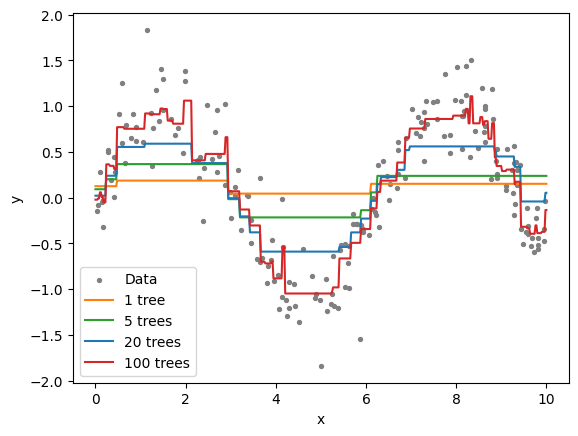

In [ ]:
starting_value, trees = boost(X_curve, y_curve, n_trees=100, learning_rate=0.1)
plt.scatter(X_curve, y_curve, s=8, color="gray", label="Data")
for n_trees, color in ((1, "tab:orange"), (5, "tab:green"), (20, "tab:blue"), (100, "tab:red")):
    plt.plot(grid, predict_boosted(starting_value, trees[:n_trees], 0.1, grid), color=color, label=f"{n_trees} tree" + ("s" if n_trees > 1 else ""))
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

One tree of depth 2, scaled by the learning rate of 0.1, barely moves the prediction away from the mean: a step of a tenth of the way. Five trees start to outline the wave, twenty follow it in broad steps, and a hundred follow it closely, already chasing a few individual points (the spikes near 2.5 and 8.5). Each tree is crude; each one corrects what the sum of the trees before it still got wrong.

scikit-learn's `GradientBoostingRegressor` does exactly this. With the same trees (`criterion="squared_error"`; its default split criterion is a slight variant), it predicts the same values:

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

library_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=2, criterion="squared_error",
                                          random_state=0).fit(X_curve, y_curve)
np.abs(library_model.predict(grid) - predict_boosted(starting_value, trees, 0.1, grid)).max()

np.float64(2.220446049250313e-15)

## The learning rate and the number of trees

On California housing, with the same training and validation sets as [Validation and model selection](../../ml-fundamentals/validation_and_model_selection.ipynb), so that the errors compare with the random forest measured there (about \$33,500). `HistGradientBoostingRegressor` is scikit-learn's fast implementation, explained below; `staged_predict` returns its predictions after each new tree, so a single training shows the whole path:

In [ ]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

housing = fetch_california_housing(as_frame=True).frame
X = housing.drop(columns="MedHouseVal")
y = housing["MedHouseVal"]
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_validation, y_train, y_validation = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)

validation_paths = {}
for learning_rate in (0.03, 0.1, 0.3, 1.0):
    model = HistGradientBoostingRegressor(learning_rate=learning_rate, max_iter=2000, early_stopping=False,
                                          random_state=42).fit(X_train, y_train)
    validation_paths[learning_rate] = [100_000 * mean_absolute_error(y_validation, prediction)
                                       for prediction in model.staged_predict(X_validation)]

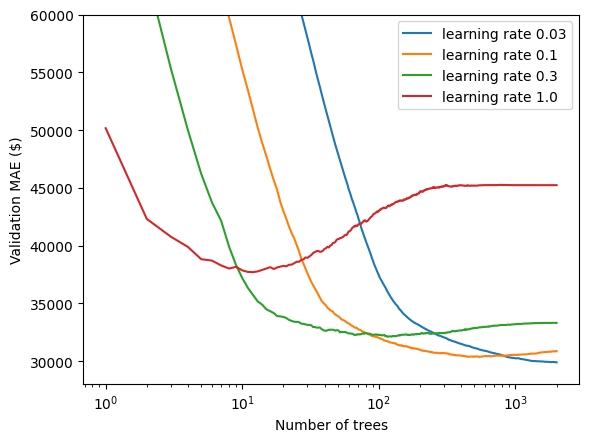

In [ ]:
for learning_rate, path in validation_paths.items():
    plt.plot(range(1, len(path) + 1), path, label=f"learning rate {learning_rate}")
plt.xscale("log")
plt.ylim(28_000, 60_000)
plt.xlabel("Number of trees")
plt.ylabel("Validation MAE ($)")
plt.legend()
plt.show()

In [ ]:
pd.DataFrame({
    learning_rate: {
        "best number of trees": int(np.argmin(path)) + 1,
        "best validation MAE ($)": min(path),
        "validation MAE after 2,000 trees ($)": path[-1],
    }
    for learning_rate, path in validation_paths.items()
}).T.rename_axis("learning rate").round(0)

,best number of trees,best validation MAE ($),"validation MAE after 2,000 trees ($)"
learning rate,,,
0.03,1999.0,29883.0,29885.0
0.10,544.0,30350.0,30849.0
0.30,117.0,32100.0,33304.0
1.00,12.0,37693.0,45226.0


Every learning rate follows the same course: the error falls fast while the first trees correct the obvious, then levels off. What differs is how fast, and what comes after. With a learning rate of 1, each tree's full correction is added: the best error comes after only 12 trees (about \$37,700), and from there every new tree fits the noise of the training rows, until the error reaches \$45,200 after 2,000 trees. With 0.3 the best is around 117 trees; with 0.1, around 544 trees and about \$30,350, after which the error creeps up slowly. With 0.03 it is still improving at 2,000 trees, and reaches the lowest error of all, about \$29,900. Smaller steps take longer, end lower and overfit more slowly: hence the usual advice, a small learning rate and as many trees as it takes.

## Early stopping

The best number of trees depends on the learning rate and on the data, so it is better found than chosen: keep adding trees while the error on held-out rows keeps falling, and stop when it no longer does. `HistGradientBoostingRegressor` does it with `early_stopping=True`: it sets aside a slice of the *training* rows (`validation_fraction`, 10% by default) and stops when that slice's error hasn't improved for `n_iter_no_change` trees. It is on by default (`early_stopping="auto"`) whenever the training set has more than 10,000 rows, as here, so even the default model checks a held-out slice, within its default ceiling of 100 trees (`max_iter`); what early stopping needs is a high ceiling. Our validation set stays out of it:

In [ ]:
early_stopped = HistGradientBoostingRegressor(learning_rate=0.1, max_iter=2000, early_stopping=True,
                                              random_state=42).fit(X_train, y_train)
early_stopped.n_iter_, 100_000 * mean_absolute_error(y_validation, early_stopped.predict(X_validation))

(192, 31410.905700744624)

Training stopped after 192 trees, at a validation MAE of about \$31,400. That is not the bottom of the curve above (about \$30,350 after 544 trees): early stopping watches a different slice of rows, and stops at the first plateau that lasts 10 trees. But it gets close without any search, and that is what it is for.

## Against the random forest

In [ ]:
import time

from sklearn.ensemble import RandomForestRegressor

contenders = {
    "random forest, 100 trees": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "gradient boosting, defaults": HistGradientBoostingRegressor(random_state=42),
    "gradient boosting, up to 2,000 trees": HistGradientBoostingRegressor(max_iter=2000, early_stopping=True, random_state=42),
}
comparison = {}
for name, model in contenders.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    comparison[name] = {"seconds to train": time.perf_counter() - start,
                        "validation MAE ($)": 100_000 * mean_absolute_error(y_validation, model.predict(X_validation))}
pd.DataFrame(comparison).T.round(1)

,seconds to train,validation MAE ($)
"random forest, 100 trees",0.3,33521.6
"gradient boosting, defaults",0.1,32300.8
"gradient boosting, up to 2,000 trees",0.3,31410.9


Gradient boosting with its default settings already beats the random forest of [Validation and model selection](../../ml-fundamentals/validation_and_model_selection.ipynb) (about \$32,300 against \$33,500), and, allowed up to 2,000 trees and stopped early at 192, more clearly (\$31,400). With its defaults it also trains in less time (the times depend on the computer): each of its trees has at most 31 leaves, while each tree of the forest grows until its leaves are pure, with thousands of them. With a smaller learning rate and more trees it would gain another \$1,500, as the curves showed. This is why it is usually the first strong model to try on a table.

## What `HistGradientBoostingRegressor` adds

`GradientBoostingRegressor` searches every possible threshold of every feature at every split, which becomes slow with tens of thousands of rows. The **histogram-based** version first sorts each feature's values into at most 255 bins, and then only considers the borders between bins: far faster, with almost no loss of accuracy. It also brings what tables of real data need:

- **Missing values** are accepted as they are: at each split, the rows with a missing value are sent to whichever side reduces the error more. No imputation is needed.
- **Categories** can be used directly, with `categorical_features`, without one-hot encoding.
- **Early stopping**, as above, is built in.

It was inspired by LightGBM; [XGBoost](xgboost.ipynb) is the library most teams use for the same method.

## Settings

| Setting (`HistGradientBoostingRegressor`) | Meaning | Effect |
| --- | --- | --- |
| `learning_rate` | how much of each tree's correction is added | smaller is usually better, but needs more trees |
| `max_iter` | maximum number of trees | with early stopping, set it high and let the validation error decide |
| `max_leaf_nodes`, `max_depth` | size of each tree | small trees (a few dozen leaves) are the norm: each only needs to capture a little |
| `min_samples_leaf` | smallest leaf | larger values smooth the model on noisy data |
| `l2_regularization` | a penalty on the leaves' values | the same idea as [Ridge](../../ml-fundamentals/regularization.ipynb), for trees |

Unlike a forest, boosting *can* overfit by adding trees, as the curve for a learning rate of 1 showed: the number of trees is a setting to find, not a resource to maximise. Its trees are trained one after another, so it can't train them in parallel as a forest does (each tree's search is parallel, though). And, like any tree model, it can't continue a trend: beyond the range of the features it was trained on, its prediction stays flat.

## Why "gradient" *(deep dive)*

For the squared error, the residual $y - \hat{y}$ is, up to a factor of 2, the **negative gradient** of the error with respect to the prediction: the direction in which each prediction should move to reduce the error fastest. Each tree therefore takes a small step downhill, not on the model's parameters, as [Gradient descent](../../ml-fundamentals/gradient_descent.ipynb) does, but on the predictions themselves.

That view is what makes the method general. For another error, the trees are fitted to the negative gradient of *that* error instead of to the plain residuals: the absolute error, which is less sensitive to outliers, or the log loss of classification. The trees' targets change, and so does the value each leaf predicts (for the absolute error, the median of its residuals instead of their mean); the procedure is the same.

## Further material

- [scikit-learn user guide: gradient boosting](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosted-trees)
- [StatQuest: Gradient Boost, part 1 (regression)](https://www.youtube.com/watch?v=3CC4N4z3GJc)
- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232.